# CESM — Regional Downscaling Inference

**Stage 2 of 2** in the DeepRisk pipeline.

This notebook takes the **intermediate 720x1440** fields produced by the
*CESM — Intermediate Downscaling* notebook and refines the **CONUS** region to a
high-resolution **960 x 1560** grid using the **L2 Transformer** (a conditioned
TransformerUNet that uses high-resolution orography). It outputs `[temperature, tp6hr]`.

```
intermediate (720x1440)  --crop CONUS-->  (96x232)  --bicubic-->  (960x1560)  --L2 Transformer-->  regional NetCDF
```

> **Fidelity:** the inference and saving code is copied verbatim from
> `run_ace_pipeline.py` (`run_l2_inference` + `save_regional`). Only markdown and plots are added.

## 1. Configuration

`INPUT_DIR` points at the intermediate outputs from Stage 1. The L2 checkpoint and the
high-resolution orography are vendored in the repo under `models/02-regional/`.

In [1]:
import os
# --- paths you may want to edit -------------------------------------------------
INPUT_DIR  = "<OUTPUT_DIR>/cesm/intermediate"    # output of the Intermediate notebook
OUTPUT_DIR = "<OUTPUT_DIR>/cesm/regional"
N_SAMPLES  = 10
SOURCE     = "CESM"

# --- model artifacts (vendored in-repo) ----------------------------------------
L2_CHECKPOINT     = "<DEEPRISK_ROOT>/models/02-regional/checkpoints/l2_transformer_v07_fft005_best.pth"
L2_OROGRAPHY_PATH = "<DEEPRISK_ROOT>/models/02-regional/hrrr_orography_snapshot_with_stats.npz"
L2_MODULE_DIR     = "<DEEPRISK_ROOT>/models/02-regional"

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Input :", INPUT_DIR)
print("Output:", OUTPUT_DIR)

Input : <OUTPUT_DIR>/cesm/intermediate
Output: <OUTPUT_DIR>/cesm/regional


## 2. Imports & constants

The CONUS crop indices and the two normalization sets are exactly those used in training:
- **input** normalization uses **ERA5** statistics (the EDM/intermediate field looks like ERA5);
- **output** de-normalization uses **HRRR** statistics (the L2 target was HRRR).

In [2]:
import sys, time, warnings
import numpy as np
import torch
import torch.nn.functional as F
import xarray as xr
import pandas as pd

sys.path.insert(0, L2_MODULE_DIR)
from models.TransformerUNet_L2 import TransformerUNet_L2_WithConditioning
warnings.filterwarnings("ignore")

# CONUS crop on the North-to-South global grid (rows 164:260 ~ 49N..25N; cols 940:1172)
CROP_LAT = slice(164, 260)   # 96 px
CROP_LON = slice(940, 1172)  # 232 px

ERA5_MEAN = [2.8765552e+02, 2.0106704e-04]   # temp (K), precip (m) — L2 INPUT normalization
ERA5_STD  = [1.1323586e+01, 1.1152735e-03]
HRRR_MEAN = [287.03198, 0.60624385]          # L2 OUTPUT de-normalization
HRRR_STD  = [11.774148, 3.5890427]
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())

torch 2.7.1+cu128 | CUDA available: True


## 3. Load the L2 Transformer + orography

In [3]:
def load_l2_model(device):
    model = TransformerUNet_L2_WithConditioning(
        in_channels=2, cond_channels=1, out_channels=2,
        down_channels=(128, 256, 512, 512), up_channels=(512, 512, 256, 128),
        trans_layers=4, trans_heads=8,
    ).to(device).eval()

    checkpoint = torch.load(L2_CHECKPOINT, map_location=device)
    state_dict = checkpoint['model_state_dict']
    if any(k.startswith('module.') for k in state_dict):     # strip DataParallel prefix
        state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
    model.load_state_dict(state_dict)

    loaded = np.load(L2_OROGRAPHY_PATH)
    oro  = torch.from_numpy(loaded['orography_snapshot']).float()
    mean = torch.from_numpy(loaded['mean']).float().view(-1, 1, 1)
    std  = torch.from_numpy(loaded['std']).float().view(-1, 1, 1)
    oro_normalized = ((oro - mean) / std).to(device)
    print("L2 model + orography loaded:", tuple(oro_normalized.shape))
    return model, oro_normalized

## 4. The L2 inference function

> **Important orientation detail.** The saved intermediate NetCDF stores latitude ascending
> (South -> North) for CF convention, but the pipeline's CONUS crop (`CROP_LAT = 164:260`)
> is defined on the model's native **North -> South** grid. So we `np.flipud` each field when
> loading to reconstruct exactly the in-memory array the monolithic pipeline cropped. This is
> the one step that differs from a naive read, and it is what makes the two-notebook split
> bit-for-bit faithful to `run_*_pipeline.py`.

In [4]:
def load_intermediate_as_NtoS(path):
    """Read sample_*_intermediate.nc and return [5, 720, 1440] in North-to-South order."""
    ds = xr.open_dataset(path)
    arr = np.stack([
        np.flipud(ds['temperature'].isel(time=0).values),
        np.flipud(ds['specific_humidity'].isel(time=0).values),
        np.flipud(ds['u_component_of_wind'].isel(time=0).values),
        np.flipud(ds['v_component_of_wind'].isel(time=0).values),
        np.flipud(ds['tp6hr'].isel(time=0).values),
    ], axis=0)
    ts = ds['time'].values[0]
    ds.close()
    return arr, ts


def run_l2_inference(edm_output_physical, l2_model, oro_normalized, device):
    """[5, 720, 1440] (N->S) -> [2, 960, 1560] (temperature K, precip)."""
    temp_crop   = edm_output_physical[0, CROP_LAT, CROP_LON]   # [96, 232]
    precip_crop = edm_output_physical[4, CROP_LAT, CROP_LON]
    assert temp_crop.shape == (96, 232), temp_crop.shape

    temp_norm   = (temp_crop   - ERA5_MEAN[0]) / ERA5_STD[0]   # ERA5-normalize the input
    precip_norm = (precip_crop - ERA5_MEAN[1]) / ERA5_STD[1]

    l2_input = np.stack([temp_norm, precip_norm], axis=0)
    l2_input = torch.from_numpy(l2_input).float().unsqueeze(0).to(device)        # [1, 2, 96, 232]
    l2_input = F.interpolate(l2_input, size=(960, 1560), mode='bicubic', align_corners=True)

    with torch.no_grad():
        prediction = l2_model(l2_input, oro_normalized.unsqueeze(0))             # [1, 2, 960, 1560]

    pred = prediction.cpu().numpy()[0]
    pred[0] = pred[0] * HRRR_STD[0] + HRRR_MEAN[0]   # de-normalize temperature (K)
    pred[1] = pred[1] * HRRR_STD[1] + HRRR_MEAN[1]   # de-normalize precipitation
    return pred

## 5. Run the regional loop & save

Each regional file is `sample_NNNNNN_regional.nc` (960x1560, gzip-compressed) with `temperature`
and `tp6hr`, on the CONUS grid (lat 49->25, lon -125->-67). The L2 stage is cheap (single forward
pass, no diffusion).

In [5]:
def save_regional(output, timestamp, sample_idx, output_dir):
    regional_lat = np.linspace(49.0, 25.0, 960)
    regional_lon = np.linspace(-125.0, -67.0, 1560)
    try:
        time_coord = [pd.Timestamp(timestamp)]
    except Exception:
        time_coord = [pd.Timestamp(str(timestamp))]
    ds = xr.Dataset({
        'temperature': (['time', 'lat', 'lon'], output[0].reshape(1, 960, 1560)),
        'tp6hr':       (['time', 'lat', 'lon'], output[1].reshape(1, 960, 1560)),
    }, coords={'time': time_coord, 'lat': regional_lat, 'lon': regional_lon})
    ds.attrs['source'] = 'CESM DeepRisk Pipeline (EDM + L2 Transformer)'
    ds.attrs['dataset_type'] = 'CESM'
    ds.attrs['sample_number'] = sample_idx
    ds.temperature.attrs['units'] = 'K'
    ds.tp6hr.attrs['units'] = 'm'
    enc = {
        'temperature': {'zlib': True, 'complevel': 4, 'chunksizes': (1, 240, 390)},
        'tp6hr':       {'zlib': True, 'complevel': 4, 'chunksizes': (1, 240, 390)},
        'time': {'units': 'days since 1900-01-01'},
    }
    fname = os.path.join(output_dir, f"sample_{sample_idx:06d}_regional.nc")
    ds.to_netcdf(fname, encoding=enc)
    return fname


assert torch.cuda.is_available(), "This notebook needs a GPU (set CUDA_VISIBLE_DEVICES)."
device = torch.device("cuda")
l2_model, l2_oro = load_l2_model(device)

for idx in range(N_SAMPLES):
    t0 = time.time()
    int_path = os.path.join(INPUT_DIR, f"sample_{idx:06d}_intermediate.nc")
    edm_phys, ts = load_intermediate_as_NtoS(int_path)        # [5, 720, 1440], N->S
    l2_output = run_l2_inference(edm_phys, l2_model, l2_oro, device)   # [2, 960, 1560]
    fname = save_regional(l2_output, ts, idx, OUTPUT_DIR)
    torch.cuda.empty_cache()
    print(f"  sample {idx}: {time.time()-t0:.1f}s -> {os.path.basename(fname)}")
print("Done. Regional files written to", OUTPUT_DIR)

L2 model + orography loaded: (1, 960, 1560)


  sample 0: 2.0s -> sample_000000_regional.nc


  sample 1: 0.8s -> sample_000001_regional.nc


  sample 2: 0.7s -> sample_000002_regional.nc


  sample 3: 0.7s -> sample_000003_regional.nc


  sample 4: 0.7s -> sample_000004_regional.nc


  sample 5: 0.7s -> sample_000005_regional.nc


  sample 6: 0.7s -> sample_000006_regional.nc


  sample 7: 0.7s -> sample_000007_regional.nc


  sample 8: 0.7s -> sample_000008_regional.nc


  sample 9: 0.7s -> sample_000009_regional.nc
Done. Regional files written to <OUTPUT_DIR>/cesm/regional


## 6. Visualize (CONUS)

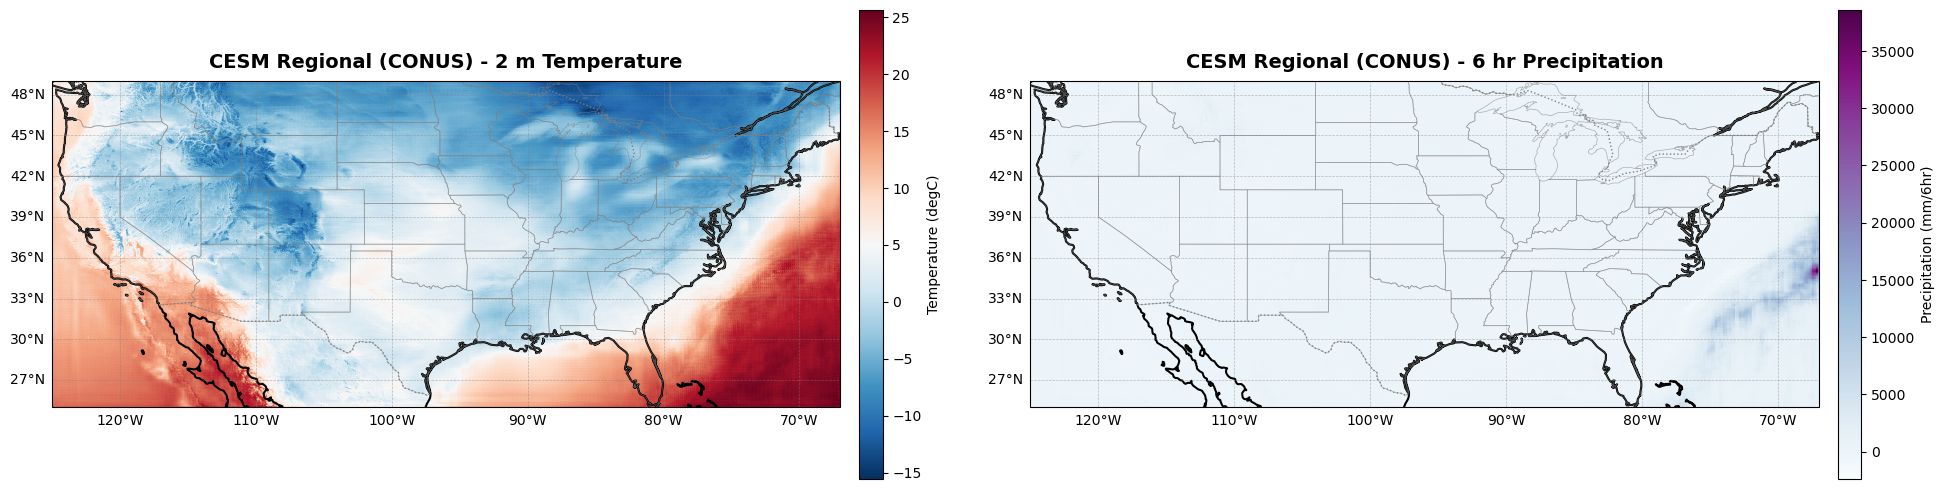

In [6]:
# CONUS regional maps, same styling as the intermediate stage but with US state
# boundaries and a CONUS map extent.
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

ds_show = xr.open_dataset(os.path.join(OUTPUT_DIR, "sample_000000_regional.nc"))
lon = ds_show.lon.values
lat = ds_show.lat.values
temp = ds_show['temperature'].isel(time=0).values - 273.15      # K -> degC
precip = ds_show['tp6hr'].isel(time=0).values * 1000.0          # m -> mm (6hr)

fig = plt.figure(figsize=(20, 7))
for i, (field, cmap, label, title) in enumerate([
        (temp,   'RdBu_r', 'Temperature (degC)',     f'{SOURCE} Regional (CONUS) - 2 m Temperature'),
        (precip, 'BuPu',   'Precipitation (mm/6hr)', f'{SOURCE} Regional (CONUS) - 6 hr Precipitation')]):
    ax = fig.add_subplot(1, 2, i + 1, projection=ccrs.PlateCarree())
    im = ax.pcolormesh(lon, lat, field, cmap=cmap, transform=ccrs.PlateCarree(), shading='auto')
    ax.add_feature(cfeature.COASTLINE, linewidth=1.5, edgecolor='black')
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='gray', alpha=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=1, edgecolor='gray', linestyle=':')
    ax.set_extent([-125, -67, 25, 49], crs=ccrs.PlateCarree())
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels = gl.right_labels = False
    cbar = plt.colorbar(im, ax=ax, label=label, shrink=0.7, pad=0.02)
    ax.set_title(title, fontsize=14, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "regional_maps_sample0.png"), dpi=300, bbox_inches='tight')
plt.show()
ds_show.close()
